In [1]:
#Importing Libraires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import warnings
warnings.filterwarnings('ignore')

In [2]:
#Loading and cleaning the Dataset
df = pd.read_csv('../data/resume_dataset.csv')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_resume_text(text):
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'\S+@\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(token) for token in tokens if token not in stop_words]
    return ' '.join(tokens)

df['cleaned_resume'] = df['Resume_str'].apply(clean_resume_text)
print("✅ Data loaded and cleaned")
print("Total samples:", len(df))

✅ Data loaded and cleaned
Total samples: 1987


In [3]:
#Creating Features and Labels
X = df['cleaned_resume']
y = df['Category']

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

tfidf = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.8,
    sublinear_tf=True
)

X_tfidf = tfidf.fit_transform(X)
print("✅ Features created")
print("Feature matrix shape:", X_tfidf.shape)
print("Number of classes:", len(label_encoder.classes_))

✅ Features created
Feature matrix shape: (1987, 3000)
Number of classes: 24


In [4]:
#Splitting Data into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)
print("✅ Data split complete")
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

✅ Data split complete
Training samples: 1589
Testing samples: 398


In [5]:
#Training Multiple Models
models = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'SVM': SVC(kernel='linear', probability=True, random_state=42)
}

results = {}
best_model = None
best_accuracy = 0
best_model_name = ""

for name, model in models.items():
    print(f"\n{'='*40}")
    print(f"🔍 Training {name}...")
    print('='*40)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy
    print(f"✅ Accuracy: {accuracy:.4f}")
    
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model = model
        best_model_name = name


🔍 Training Naive Bayes...
✅ Accuracy: 0.5251

🔍 Training Logistic Regression...
✅ Accuracy: 0.5980

🔍 Training SVM...
✅ Accuracy: 0.6131


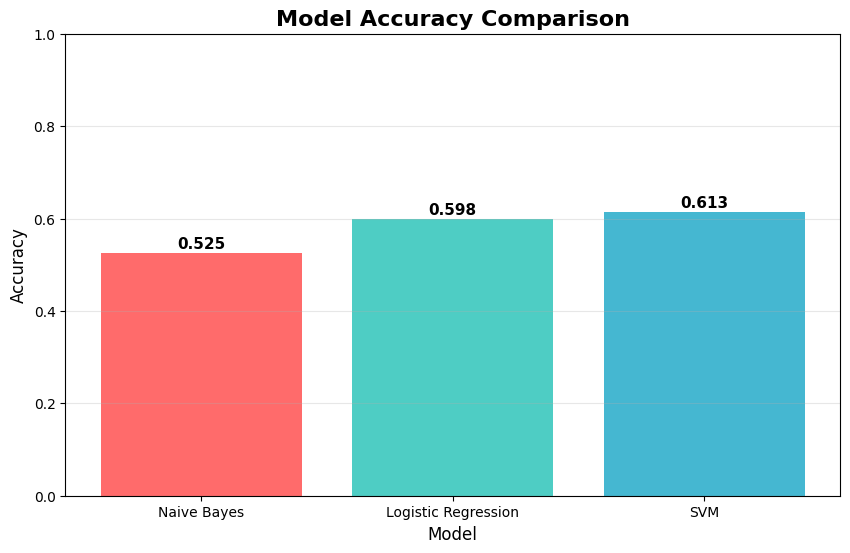


🏆 BEST MODEL: SVM
🎯 Accuracy: 0.6131


In [6]:
#Comparing Model Performance
plt.figure(figsize=(10, 6))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
bars = plt.bar(results.keys(), results.values(), color=colors)
plt.title('Model Accuracy Comparison', fontsize=16, fontweight='bold')
plt.xlabel('Model', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.ylim(0, 1.0)
for bar, (name, acc) in zip(bars, results.items()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{acc:.3f}', ha='center', fontsize=11, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.show()

print(f"\n{'='*40}")
print(f"🏆 BEST MODEL: {best_model_name}")
print(f"🎯 Accuracy: {best_accuracy:.4f}")
print('='*40)

In [8]:
#Saving Models for Streamlit App
import joblib
import os


os.makedirs('../models', exist_ok=True)

# Save all models
joblib.dump(best_model, '../models/best_model.pkl')
joblib.dump(tfidf, '../models/tfidf_vectorizer.pkl')
joblib.dump(label_encoder, '../models/label_encoder.pkl')

print("✅ ALL MODELS SAVED SUCCESSFULLY")
print('='*40)
print("Files saved in 'models' folder:")
print("   1. best_model.pkl  - Best classifier")
print("   2. tfidf_vectorizer.pkl  - TF-IDF converter")
print("   3. label_encoder.pkl  - Category encoder")
print('='*40)

✅ ALL MODELS SAVED SUCCESSFULLY
Files saved in 'models' folder:
   1. best_model.pkl  - Best classifier
   2. tfidf_vectorizer.pkl  - TF-IDF converter
   3. label_encoder.pkl  - Category encoder


In [7]:
#Detailed Classification Report
y_pred_best = best_model.predict(X_test)
print("📊 DETAILED CLASSIFICATION REPORT")
print('='*60)
print(classification_report(y_test, y_pred_best, target_names=label_encoder.classes_))
print('='*60)

📊 DETAILED CLASSIFICATION REPORT
                        precision    recall  f1-score   support

            ACCOUNTANT       0.68      0.94      0.79        18
              ADVOCATE       0.71      0.56      0.62        18
           AGRICULTURE       0.83      0.45      0.59        11
               APPAREL       0.33      0.20      0.25        15
                  ARTS       0.38      0.35      0.36        17
            AUTOMOBILE       0.00      0.00      0.00         6
              AVIATION       0.73      0.58      0.65        19
               BANKING       0.50      0.67      0.57        18
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.42      0.58      0.49        19
                  CHEF       0.84      0.84      0.84        19
          CONSTRUCTION       0.92      0.75      0.83        16
            CONSULTANT       0.42      0.26      0.32        19
              DESIGNER       0.87      0.72      0.79        18
      

In [8]:
import os
print("Current directory:", os.getcwd())
print("\nChecking for models folder...")
if os.path.exists('../models'):
    print("✅ models folder exists")
    print("\nFiles in models folder:")
    for file in os.listdir('../models'):
        print(f"   - {file}")
else:
    print("❌ models folder does NOT exist")
    
    # Create models folder
    os.makedirs('../models', exist_ok=True)
    print("✅ Created models folder")

Current directory: ../notebooks

Checking for models folder...
✅ models folder exists

Files in models folder:
   - tfidf_vectorizer.pkl
   - label_encoder.pkl
   - best_model.pkl


In [9]:
import joblib

# Save models
joblib.dump(best_model, '../models/best_model.pkl')
joblib.dump(tfidf, '../models/tfidf_vectorizer.pkl')
joblib.dump(label_encoder, '../models/label_encoder.pkl')

print("✅ Models saved successfully!")
print("Files saved:")
print("   - ../models/best_model.pkl")
print("   - ../models/tfidf_vectorizer.pkl")
print("   - ../models/label_encoder.pkl")

# Verify they exist
print("\nVerifying...")
if os.path.exists('../models/best_model.pkl'):
    print("✅ All files verified")
else:
    print("❌ Error: Files not saved")

✅ Models saved successfully!
Files saved:
   - ../models/best_model.pkl
   - ../models/tfidf_vectorizer.pkl
   - ../models/label_encoder.pkl

Verifying...
✅ All files verified


In [13]:
import joblib
import os

# Exact path from your output
models_path = "../models"

# Create folder if it doesn't exist
os.makedirs(models_path, exist_ok=True)

print(f"Saving models to: {models_path}")

# Save models
joblib.dump(best_model, os.path.join(models_path, 'best_model.pkl'))
joblib.dump(tfidf, os.path.join(models_path, 'tfidf_vectorizer.pkl'))
joblib.dump(label_encoder, os.path.join(models_path, 'label_encoder.pkl'))

print("✅ Models saved successfully!")

# Verify
print("\nFiles in models folder:")
if os.path.exists(models_path):
    for file in os.listdir(models_path):
        if file.endswith('.pkl'):
            file_path = os.path.join(models_path, file)
            file_size = os.path.getsize(file_path) / 1024
            print(f"   - {file} ({file_size:.1f} KB)")

Saving models to: ../models
✅ Models saved successfully!

Files in models folder:
   - tfidf_vectorizer.pkl (115.0 KB)
   - label_encoder.pkl (0.7 KB)
   - best_model.pkl (5270.8 KB)


In [11]:
import glob
print("Models found:", glob.glob('../models/*.pkl'))

Models found: ['../models/tfidf_vectorizer.pkl', '../models/label_encoder.pkl', '../models/best_model.pkl']


In [12]:
import os
project_path = os.path.expanduser("~/Desktop/resume-classification-project")
print(f"Your project path is: {project_path}")
print(f"Models should be saved to: {project_path}/models/")

Your project path is: ..
Models should be saved to: ../models/
